# Introduction

In this tutorial, we demonstrate how to use **SpatialZoomer** to identify multi-scale spatial structures in single-cell resolved spatial transcriptomics (ST) data, ranging from cells to niches and tissue domains.  

For illustration, we use a Xenium Prime FFPE human cervical cancer sample (840,387 cells, 5,101 genes). After quality control, 801,131 cells and 5,098 genes are retained. The recorded analysis took approximately 55 minutes.

#### Table of Contents
- [0. Installation, package loading, and data preprocessing](#0-installation-package-loading-and-data-preprocessing)
- [1. Extract multi-scale features via spectral graph signal processing](#1-extract-multi-scale-features-via-spectral-graph-signal-processing)
- [2. Identify critical scales automatically](#2-identify-critical-scales-automatically)
- [3. Identify spatial structures using two-step clustering](#3-identify-spatial-structures-using-two-step-clustering)
  - [Results and Analysis](#results-and-analysis)
  - [Results in the save_path Folder](#results-in-the-save_path-folder)
- [4. Scale-to-distance mapping](#4-scale-to-distance-mapping)

### 0. Installation, package loading, and data preprocessing

For detailed installation instructions, environment setup, and package dependencies, please refer to the [SpatialZoomer GitHub repository](https://github.com/Li-Xinqi/SpatialZoomer.git).

Install or upgrade to the latest version of SpatialZoomer:

```bash
python -m pip install --upgrade spatialzoomer
```

Import the installed package:

```python
import spatialzoomer as sz
```

Next, load the spatial transcriptomics data, perform cell- and gene-level quality control, and normalize the expression matrix.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import seaborn as sns
import pandas as pd
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

Please set the following basic information:
* `runLabel`: The name of the dataset.

* `save_path`: A path to save the analysis results.

* `adata`: An **AnnData** object storing single-cell resolved spatial transcriptomics data,  

  - `adata.X` contains the raw, unnormalized transcript count matrix.  
  
  - `adata.obsm['spatial']` stores the spatial coordinates.  
 
The **input ST data** in AnnData format are available in the current Zenodo archive and can also be downloaded from [Google Drive](https://drive.google.com/file/d/1Q1mrnFx6rfgMIPoVC5W8PBJeuULE2IQd/view?usp=drive_link).

The original data can be downloaded from the [official Xenium Prime cervical cancer dataset page](https://www.10xgenomics.com/datasets/xenium-prime-ffpe-human-cervical-cancer).

In [2]:
runLabel = 'Xenium_Prime_Cervical_Cancer_FFPE'
save_path = './Outputs/' + runLabel+'_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad(runLabel + '_anndata.h5ad')
adata

AnnData object with n_obs × n_vars = 840387 × 5101
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

<Axes: title={'center': 'Nucleus ratio'}, ylabel='Count'>

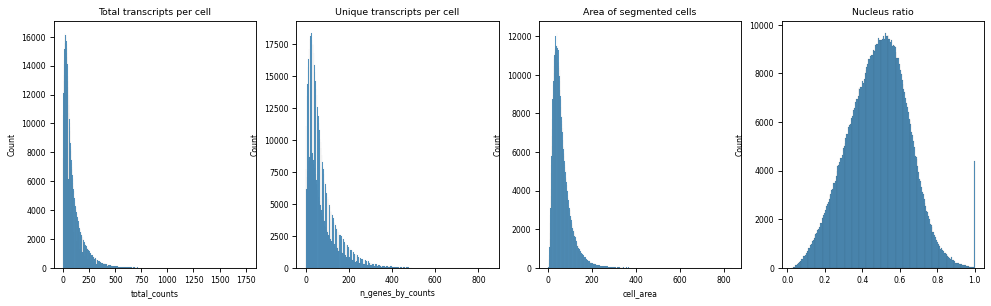

In [3]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3],
)

**Quality control and normalization**

* `filter_cells` removes low-quality cells with insufficient transcript and gene detection;
* Cells with missing nuclear area values are removed;
* `filter_genes` removes genes detected in too few cells;
* `sz.Preprocess` stores the original count matrix in `adata.layers["counts"]`, performs total-count normalization, and applies a log(1+x) transformation.

In [4]:
# Quality control on cells
sc.pp.filter_cells(adata, min_counts = 5)
sc.pp.filter_cells(adata, min_genes = 5)
adata = adata[~adata.obs['nucleus_area'].isna(), :]

# Quality control on genes
sc.pp.filter_genes(adata, min_cells = 5)

# Normalization
adata = sz.Preprocess(adata)
adata

AnnData object with n_obs × n_vars = 801131 × 5098
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p'
    obsm: 'spatial'
    layers: 'counts'

### 1. Extract multi-scale features via spectral graph signal processing

- Obtain **graph signals** (cell programs) from transcriptomic data using dimensionality reduction with **NMF**.

- Construct a **spatial neighbor graph** based on the physical proximity of cells.

- Apply a bank of **heat-kernel-based low-pass filters** to extract features across multiple spatial scales.

Perform NMF to obtain graph signals. `n_components` specifies the dimensionality of the graph signals.

In [ ]:
adata = sz.performDR(adata, type = 'NMF', n_components=50)

Time taken to perform NMF: 344.9898 seconds


Initialize the SpatialZoomer object and define candidate scales. Here, `save_intermediate=False` reduces storage use by not saving the transformed-signal `.h5` file or intermediate K-Means `.h5ad` objects.

Perform spectral graph signal processing using `X_nmf`, 20 spatial neighbors, and the candidate scales defined below. `pattern='auto'` is recommended for all datasets, while `pattern='None'` can be used for Xenium samples.

### 2. Identify critical scales automatically

SpatialZoomer partitions the cross-scale similarity map into contiguous blocks and automatically selects critical scales representing the transitions and centers of these blocks.

### 3. Identify spatial structures using two-step clustering

Mini-Batch K-Means first generates 10,000 metacells, after which Leiden clustering identifies fine-grained clusters. A higher resolution yields more clusters. Testing multiple resolution values is recommended.

Median similarities:  5.413613841315116
Time taken to construct spatial_knn: 6.8018 seconds
Time taken to perform spectral graph filter bank: 386.2617 seconds


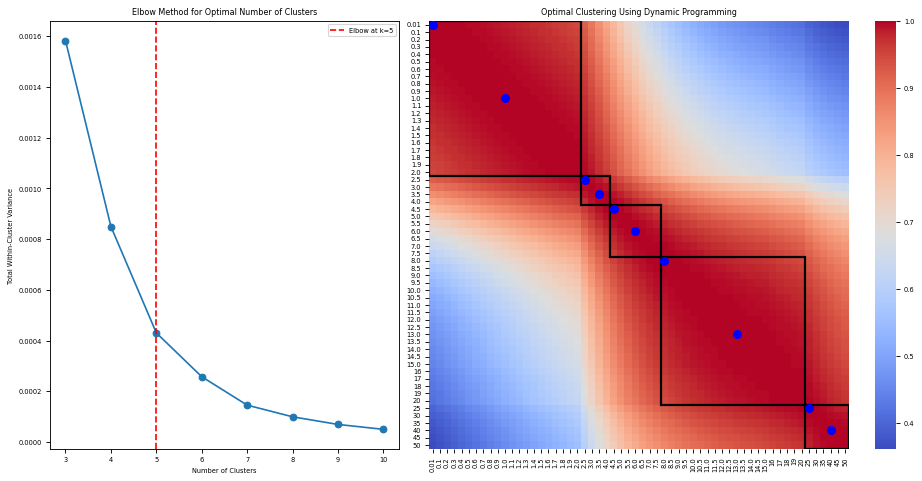

The optimal number of clusters is: 5
Typical scales: [0.01, 1.0, 2.5, 3.5, 4.5, 6.0, 8.0, 13.0, 25, 40]
Time taken to perform identification of typical scales: 34.3760 seconds
Time taken to perform UMAP and clustering for raw signal: 250.7705 seconds
Time taken to perform clustering for signal at scale 0.01: 155.2898 seconds
Time taken to perform clustering for signal at scale 1.0: 138.7870 seconds
Time taken to perform clustering for signal at scale 2.5: 145.8623 seconds
Time taken to perform clustering for signal at scale 3.5: 130.1839 seconds
Time taken to perform clustering for signal at scale 4.5: 135.2791 seconds
Time taken to perform clustering for signal at scale 6.0: 132.7592 seconds
Time taken to perform clustering for signal at scale 8.0: 138.5765 seconds
Time taken to perform clustering for signal at scale 13.0: 170.1765 seconds
Time taken to perform clustering for signal at scale 25.0: 150.2291 seconds
Time taken to perform clustering for signal at scale 40.0: 150.5846 sec

In [ ]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path, save_intermediate=False)
sz_analyzer.dpi = use_dpi

scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

sz_analyzer.multiscale_transform(use_rep='X_nmf', n_neighbors=20, scales=scales, pattern = 'None')
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)

resolutions = [0.6, 0.8, 1]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions)

The clustering and UMAP results at each critical scale are stored in `sz_analyzer.adata`. Clustering results are stored in `sz_analyzer.adata.obs` as `leiden_<scale>_res<resolution>`, and UMAP embeddings are stored in `sz_analyzer.adata.obsm` as `X_umap_<scale>`.

### Results and Analysis

- In the **raw signal space** (Scale 0.0), clustering reflects the single-cell scale, enabling the identification of cell types or states.

- **As the scale increases**, each cell progressively integrates spatial context from broader neighborhoods, capturing spatial structures such as niches and tissue domains.

- At excessively large scales, signals become over-smoothed and may no longer preserve meaningful biological distinctions.

Note: Results may slightly differ from those reported in the paper because NMF, Leiden, and UMAP involve randomness. Although random seeds are set, minor variations can still occur across environments or devices.

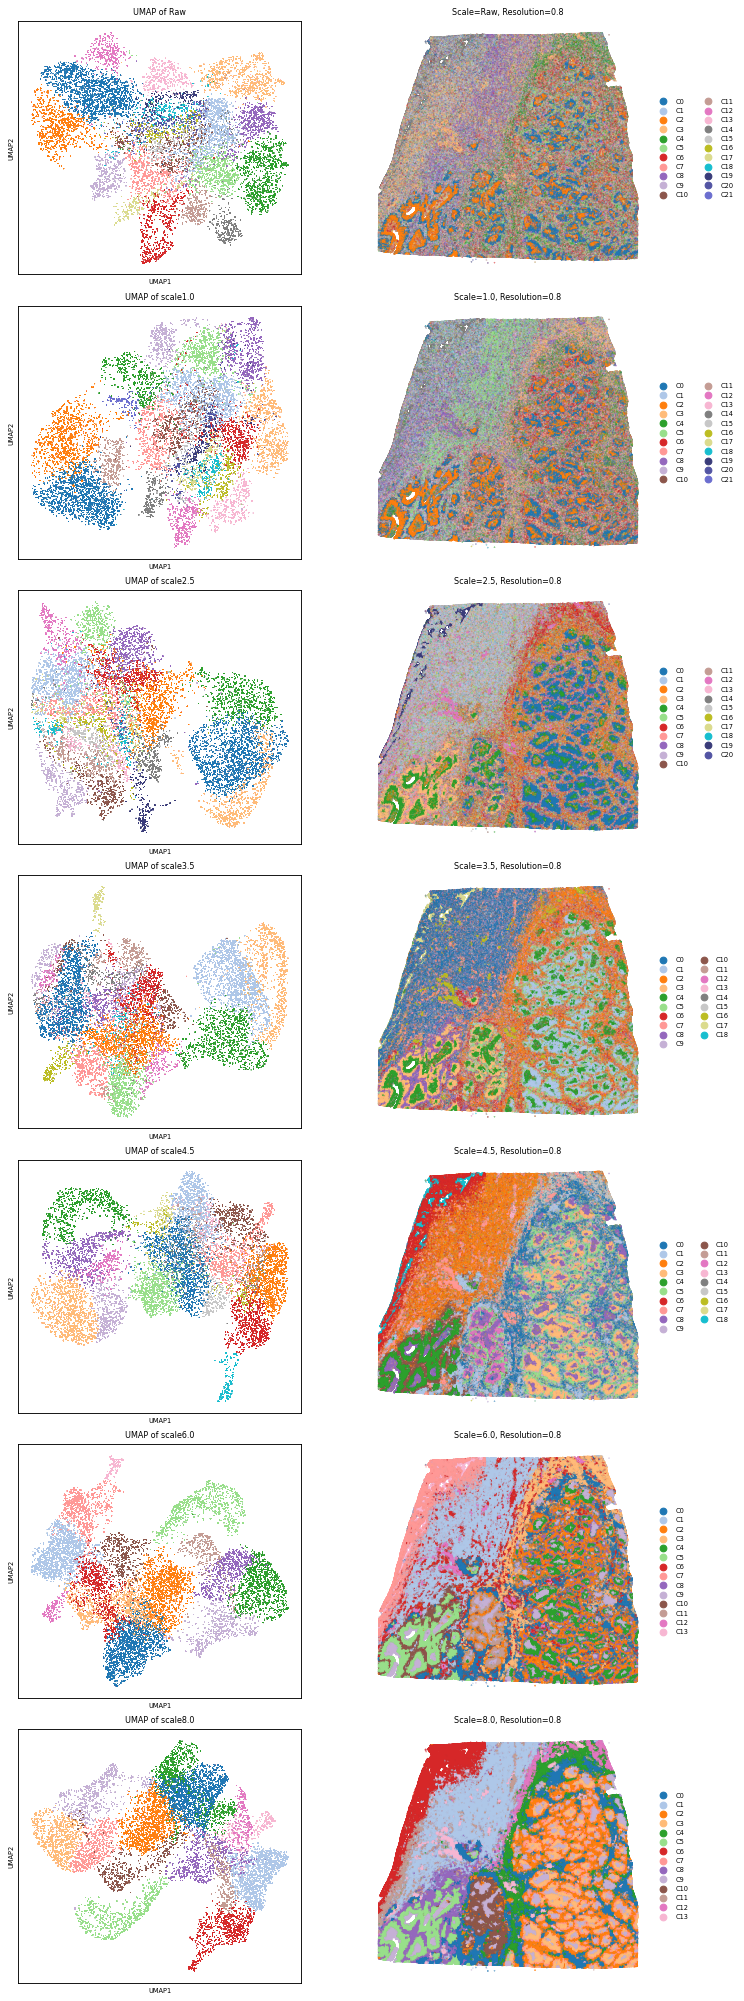

In [7]:
sz_analyzer.plot_multiscale_clusters(resolution=0.8, figsize=(10, 25), min_scale = 0.5, max_scale = 10,
                                     pt_size_umap= 1, pt_size_scatter= 0.1)

Quantify the contributions of spatial proximity and transcriptomic similarity to clustering outcomes across different scales.

Median similarities:  4.99999998975568
Time taken to construct expr_knn: 757.6852 seconds


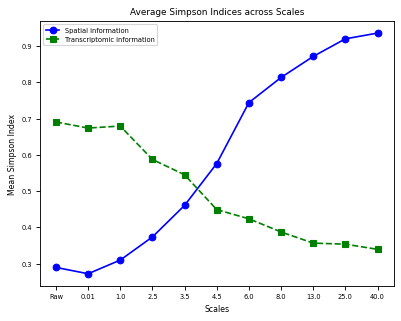

In [8]:
sz_analyzer.plot_simpson(resolution = 0.8)

The `sz_analyzer.adata` object is compatible with the Python ecosystem for scRNA-seq and ST data, including packages such as **scanpy** and **squidpy**, and can be used directly for downstream analysis and visualization.

In [9]:
sz_analyzer.adata.write(save_path + runLabel + '_SpatialZoomer.h5ad')
sz_analyzer.adata

AnnData object with n_obs × n_vars = 801131 × 5098
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.6', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale0.01', 'leiden_scale0.01_res0.6', 'leiden_scale0.01_res0.8', 'leiden_scale0.01_res1', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.6', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'Kmeans_scale2.5', 'leiden_scale2.5_res0.6', 'leiden_scale2.5_res0.8', 'leiden_scale2.5_res1', 'Kmeans_scale3.5', 'leiden_scale3.5_res0.6', 'leiden_scale3.5_res0.8', '

### Results in the `save_path` folder

The following output files are generated and saved in the `save_path` directory:

- `<runLabel>_SpatialZoomer.h5ad`: The core AnnData object containing all multi-scale clustering results, recommended for downstream analyses.

- `Typical_scales.pdf`: Visualization of critical scale selection.

- `Typical_scales.csv`: Table recording the selected critical scales.

- `Average_Simpson_Indices_across_Scales.pdf`: Contributions of spatial proximity and transcriptomic similarity across scales.

### 4. Scale-to-distance mapping

After running SpatialZoomer, `sz.mapping_scale_to_distance()` can be used to estimate the effective physical range corresponding to each scale. The resulting distances use the same units as `adata.obsm['spatial']`.

The function summarizes how spatial signals diffuse with distance and generates heatmaps for all cells and three cell-density groups: Low (lowest 10%), Medium (middle 80%), and High (highest 10%).

Results are saved in the `<out_dir>/scale_to_distance_mapping/` folder.

Calculate density
Using percentile: 10 (q10=6.00, q90=20.00)
Density_group
Medium    622303
High       93630
Low        85198
Name: count, dtype: int64
Computing overall heatmap (all 2000 seeds)...
Computing heatmap for group Low (368 seeds)...
Computing heatmap for group Medium (1303 seeds)...
Computing heatmap for group High (329 seeds)...
[Saved] All group data -> ./Outputs/Xenium_Prime_Cervical_Cancer_FFPE_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_All.csv, E95_distance_All.csv
[Saved] Low group data -> ./Outputs/Xenium_Prime_Cervical_Cancer_FFPE_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_Low.csv, E95_distance_Low.csv
[Saved] Medium group data -> ./Outputs/Xenium_Prime_Cervical_Cancer_FFPE_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_Medium.csv, E95_distance_Medium.csv
[Saved] High group data -> ./Outputs/Xenium_Prime_Cervical_Cancer_FFPE_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_High.csv

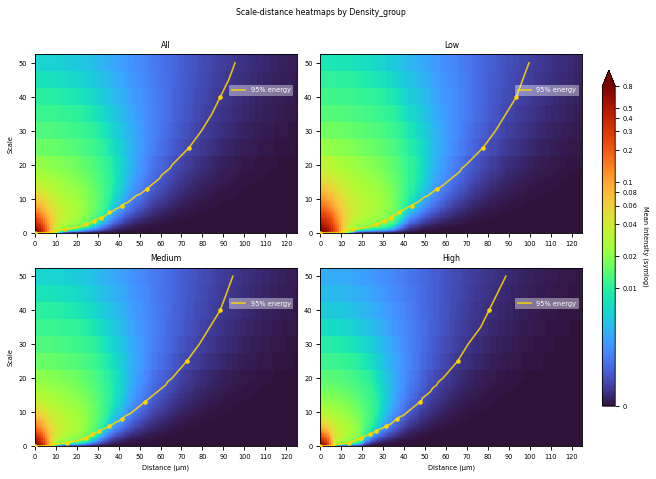

Time taken to perform physical distance analysis: 289.0990 seconds


In [10]:
# Run scale-to-distance mapping
# Uses sz_analyzer.adata which already contains spatial_knn (obsp) and
# X_umap_scale* embeddings (obsm) from the SpatialZoomer pipeline above.
out = sz.mapping_scale_to_distance(
    adata=sz_analyzer.adata,
    out_dir=save_path,
    run_label=runLabel,
    plot_sampling_rounds=False,          # number of rounds to run for sampling-based mapping
    typical_scales=None,        # auto-extract typical scales from obsm (X_umap_scale*)
    plot_typical_scales=True,   # mark typical scales on the heatmap
    normalize_rows=False,
    show=True,
    dpi=use_dpi,
    colorbar_vmax_symlog = 0.8
)